# Auditoría y conciliación de datos de ventas e inventario

## Descripción

Este proyecto analiza tres fuentes de datos sintéticas de una empresa distribuidora:

- Catálogo de productos.
- Registro de ventas.
- Inventario por sucursal.

El objetivo es identificar datos faltantes, duplicados, formatos inconsistentes, valores inválidos y diferencias entre fuentes. Posteriormente, los datos serán limpiados y conciliados utilizando Python, pandas, Excel y Power Query.

## Fuentes

Los archivos utilizados son datos sintéticos generados específicamente para este proyecto. No contienen información real ni confidencial.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# Configuración para mostrar todas las columnas
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Estilo para los gráficos
sns.set_theme(style="whitegrid")

# Localizar la carpeta principal del proyecto
ruta_proyecto = Path.cwd()

if not (ruta_proyecto / "data" / "raw").exists():
    ruta_proyecto = ruta_proyecto.parent

ruta_raw = ruta_proyecto / "data" / "raw"

print(f"Ruta del proyecto: {ruta_proyecto}")
print(f"Ruta de los datos: {ruta_raw}")

Ruta del proyecto: c:\Users\Henry\OneDrive\Escritorio\python\data-quality-sales-inventory
Ruta de los datos: c:\Users\Henry\OneDrive\Escritorio\python\data-quality-sales-inventory\data\raw


In [3]:
catalogo = pd.read_csv(
    ruta_raw / "catalogo_productos.csv",
    encoding="utf-8-sig",
)

ventas = pd.read_csv(
    ruta_raw / "ventas.csv",
    encoding="utf-8-sig",
)

inventario = pd.read_excel(
    ruta_raw / "inventario.xlsx",
    sheet_name="Inventario",
)

print("ARCHIVOS CARGADOS CORRECTAMENTE")
print(f"Catálogo: {catalogo.shape}")
print(f"Ventas: {ventas.shape}")
print(f"Inventario: {inventario.shape}")

ARCHIVOS CARGADOS CORRECTAMENTE
Catálogo: (21, 5)
Ventas: (505, 8)
Inventario: (61, 6)


In [4]:
print("CATÁLOGO DE PRODUCTOS")
display(catalogo.head())

print("VENTAS")
display(ventas.head())

print("INVENTARIO")
display(inventario.head())

CATÁLOGO DE PRODUCTOS


,producto_id,nombre_producto,categoria,precio_estandar,activo
0,P001,Piña dorada,Frutas,1250.0,True
1,P002,Mango,Frutas,1100.0,True
2,P003,Papaya,Frutas,950.0,True
3,P004,Banano,Frutas,700.0,True
4,P005,Sandía,Frutas,1800.0,True


VENTAS


,venta_id,fecha,sucursal,producto_id,cantidad,vendedor,canal,precio_unitario
0,V00001,2026-01-17,Heredia,P017,8,María,En línea,1424.06
1,V00002,2026-05-21,Alajuela,P015,4,Ana,Tienda,1830.60
2,V00003,2026-04-29,San José,P012,4,Carlos,En línea,1332.57
3,V00004,2026-03-21,San José,P018,5,Daniela,Tienda,1191.01
4,V00005,2026-03-20,Heredia,P003,9,José,Tienda,979.65


INVENTARIO


,sucursal,producto_id,stock_sistema,stock_fisico,fecha_corte,responsable
0,Heredia,P001,93,97,2026-06-30,Laura
1,Heredia,P002,28,27,2026-06-30,Laura
2,Heredia,P003,204,209,2026-06-30,Laura
3,Heredia,P004,77,79,2026-06-30,Laura
4,Heredia,P005,63,-8,2026-06-30,Laura


## Auditoría inicial de la estructura

Antes de limpiar los datos, se revisa la cantidad de filas y columnas de cada fuente.

In [5]:
resumen_estructura = pd.DataFrame({
    "fuente": [
        "Catálogo de productos",
        "Ventas",
        "Inventario"
    ],
    "filas": [
        catalogo.shape[0],
        ventas.shape[0],
        inventario.shape[0]
    ],
    "columnas": [
        catalogo.shape[1],
        ventas.shape[1],
        inventario.shape[1]
    ]
})

display(resumen_estructura)

,fuente,filas,columnas
0,Catálogo de productos,21,5
1,Ventas,505,8
2,Inventario,61,6


## Detección de valores faltantes

Se revisan todas las columnas para identificar datos vacíos que puedan afectar el análisis y la conciliación entre las fuentes.

In [6]:
def obtener_faltantes(df, fuente):
    faltantes = df.isna().sum()

    resultado = pd.DataFrame({
        "fuente": fuente,
        "columna": faltantes.index,
        "valores_faltantes": faltantes.values,
        "porcentaje_faltante": (
            faltantes.values / len(df) * 100
        ).round(2)
    })

    return resultado[
        resultado["valores_faltantes"] > 0
    ]


resumen_faltantes = pd.concat([
    obtener_faltantes(catalogo, "Catálogo de productos"),
    obtener_faltantes(ventas, "Ventas"),
    obtener_faltantes(inventario, "Inventario")
], ignore_index=True)

display(resumen_faltantes)

,fuente,columna,valores_faltantes,porcentaje_faltante
0,Catálogo de productos,nombre_producto,1,4.76
1,Ventas,producto_id,4,0.79
2,Ventas,vendedor,1,0.20
3,Inventario,producto_id,1,1.64


## Detección de registros duplicados

Se identifican filas completamente repetidas. También se calcula cuántas filas están involucradas, incluyendo el registro original y sus copias.

In [7]:
resumen_duplicados = pd.DataFrame({
    "fuente": [
        "Catálogo de productos",
        "Ventas",
        "Inventario"
    ],
    "copias_duplicadas": [
        catalogo.duplicated().sum(),
        ventas.duplicated().sum(),
        inventario.duplicated().sum()
    ],
    "filas_involucradas": [
        catalogo.duplicated(keep=False).sum(),
        ventas.duplicated(keep=False).sum(),
        inventario.duplicated(keep=False).sum()
    ]
})

display(resumen_duplicados)

,fuente,copias_duplicadas,filas_involucradas
0,Catálogo de productos,1,2
1,Ventas,5,10
2,Inventario,1,2


## Revisión de columnas y tipos de datos

Se documenta la estructura de cada fuente para identificar tipos de datos incorrectos y preparar las validaciones de calidad.

In [8]:
def obtener_estructura(df, fuente):
    return pd.DataFrame({
        "fuente": fuente,
        "columna": df.columns,
        "tipo_dato": df.dtypes.astype(str).values,
        "registros_no_nulos": df.notna().sum().values,
        "valores_faltantes": df.isna().sum().values,
        "valores_unicos": df.nunique(dropna=True).values
    })


estructura_completa = pd.concat([
    obtener_estructura(catalogo, "Catálogo de productos"),
    obtener_estructura(ventas, "Ventas"),
    obtener_estructura(inventario, "Inventario")
], ignore_index=True)

display(estructura_completa)

,fuente,columna,tipo_dato,registros_no_nulos,valores_faltantes,valores_unicos
0,Catálogo de productos,producto_id,str,21,0,20
1,Catálogo de productos,nombre_producto,str,20,1,19
2,Catálogo de productos,categoria,str,21,0,6
3,Catálogo de productos,precio_estandar,float64,21,0,20
4,Catálogo de productos,activo,bool,21,0,1
5,Ventas,venta_id,str,505,0,500
6,Ventas,fecha,str,505,0,169
7,Ventas,sucursal,str,505,0,6
8,Ventas,producto_id,str,501,4,21
9,Ventas,cantidad,int64,505,0,17


## Validación de fechas y valores numéricos

Se aplican reglas de negocio para detectar precios, cantidades y existencias inválidas, así como fechas que no puedan convertirse correctamente.

In [9]:
# Convertir temporalmente las fechas para comprobar su formato
fechas_ventas_convertidas = pd.to_datetime(
    ventas["fecha"],
    errors="coerce"
)

resumen_reglas_numericas = pd.DataFrame({
    "regla_validada": [
        "Precio estándar mayor que cero",
        "Cantidad vendida mayor que cero",
        "Precio unitario mayor que cero",
        "Stock del sistema no negativo",
        "Stock físico no negativo",
        "Fecha de venta con formato válido"
    ],
    "registros_invalidos": [
        (catalogo["precio_estandar"] <= 0).sum(),
        (ventas["cantidad"] <= 0).sum(),
        (ventas["precio_unitario"] <= 0).sum(),
        (inventario["stock_sistema"] < 0).sum(),
        (inventario["stock_fisico"] < 0).sum(),
        fechas_ventas_convertidas.isna().sum()
    ]
})

display(resumen_reglas_numericas)

,regla_validada,registros_invalidos
0,Precio estándar mayor que cero,1
1,Cantidad vendida mayor que cero,3
2,Precio unitario mayor que cero,2
3,Stock del sistema no negativo,0
4,Stock físico no negativo,1
5,Fecha de venta con formato válido,1


## Integridad referencial entre las fuentes

Se valida que todos los identificadores de producto utilizados en ventas e inventario existan en el catálogo maestro de productos.

In [10]:
# Normalización temporal de identificadores
ids_catalogo = set(
    catalogo["producto_id"]
    .dropna()
    .astype("string")
    .str.strip()
    .str.upper()
)

ids_ventas = (
    ventas["producto_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

ids_inventario = (
    inventario["producto_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Registros con identificadores que no existen en el catálogo
ventas_sin_catalogo = (
    ids_ventas.notna()
    & ~ids_ventas.isin(ids_catalogo)
)

inventario_sin_catalogo = (
    ids_inventario.notna()
    & ~ids_inventario.isin(ids_catalogo)
)

resumen_integridad = pd.DataFrame({
    "validacion": [
        "Productos de ventas inexistentes en catálogo",
        "Productos de inventario inexistentes en catálogo"
    ],
    "registros_inconsistentes": [
        ventas_sin_catalogo.sum(),
        inventario_sin_catalogo.sum()
    ]
})

display(resumen_integridad)

print(
    "Identificadores inválidos en ventas:",
    sorted(ids_ventas[ventas_sin_catalogo].unique().tolist())
)

print(
    "Identificadores inválidos en inventario:",
    sorted(ids_inventario[inventario_sin_catalogo].unique().tolist())
)

,validacion,registros_inconsistentes
0,Productos de ventas inexistentes en catálogo,2
1,Productos de inventario inexistentes en catálogo,0


Identificadores inválidos en ventas: ['P999']
Identificadores inválidos en inventario: []


## Consistencia de campos de texto

Se comparan los valores originales con una versión normalizada para detectar diferencias causadas por espacios, mayúsculas o minúsculas.

In [11]:
campos_texto = [
    ("Catálogo de productos", catalogo, "categoria"),
    ("Ventas", ventas, "sucursal"),
    ("Ventas", ventas, "canal"),
    ("Ventas", ventas, "vendedor"),
    ("Inventario", inventario, "sucursal"),
    ("Inventario", inventario, "responsable")
]

resultados_texto = []

for fuente, dataframe, columna in campos_texto:
    valores_originales = (
        dataframe[columna]
        .dropna()
        .astype("string")
    )

    valores_normalizados = (
        valores_originales
        .str.strip()
        .str.lower()
    )

    resultados_texto.append({
        "fuente": fuente,
        "columna": columna,
        "valores_originales": valores_originales.nunique(),
        "valores_normalizados": valores_normalizados.nunique(),
        "posible_inconsistencia":
            valores_originales.nunique()
            != valores_normalizados.nunique()
    })

resumen_texto = pd.DataFrame(resultados_texto)

display(resumen_texto)

for fuente, dataframe, columna in campos_texto:
    valores = sorted(
        dataframe[columna]
        .dropna()
        .astype("string")
        .unique()
        .tolist()
    )

    print(f"\n{fuente} - {columna}:")
    print([repr(valor) for valor in valores])

,fuente,columna,valores_originales,valores_normalizados,posible_inconsistencia
0,Catálogo de productos,categoria,6,5,True
1,Ventas,sucursal,6,3,True
2,Ventas,canal,3,3,False
3,Ventas,vendedor,5,5,False
4,Inventario,sucursal,4,3,True
5,Inventario,responsable,3,3,False



Catálogo de productos - categoria:
["'Bebidas'", "'Congelados'", "'Frutas'", "'Granos'", "'Vegetales'", "'vegetales'"]

Ventas - sucursal:
["' heredia '", "'Alajuela'", "'HEREDIA'", "'Heredia'", "'San José'", "'san josé'"]

Ventas - canal:
["'En línea'", "'Teléfono'", "'Tienda'"]

Ventas - vendedor:
["'Ana'", "'Carlos'", "'Daniela'", "'José'", "'María'"]

Inventario - sucursal:
["'Alajuela'", "'Heredia'", "'San José'", "'san josé'"]

Inventario - responsable:
["'Laura'", "'Miguel'", "'Sofía'"]


## Limpieza de datos — duplicados y textos

Se crean copias de trabajo para conservar intactos los archivos originales. Primero se eliminan duplicados exactos y se normalizan identificadores y campos de texto.

In [12]:
# Copias de trabajo
catalogo_limpio = catalogo.copy()
ventas_limpias = ventas.copy()
inventario_limpio = inventario.copy()

filas_antes = {
    "Catálogo de productos": len(catalogo_limpio),
    "Ventas": len(ventas_limpias),
    "Inventario": len(inventario_limpio)
}

# Eliminar duplicados exactos
catalogo_limpio = catalogo_limpio.drop_duplicates().copy()
ventas_limpias = ventas_limpias.drop_duplicates().copy()
inventario_limpio = inventario_limpio.drop_duplicates().copy()

# Normalizar identificadores
catalogo_limpio["producto_id"] = (
    catalogo_limpio["producto_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

ventas_limpias["producto_id"] = (
    ventas_limpias["producto_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

inventario_limpio["producto_id"] = (
    inventario_limpio["producto_id"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Normalizar catálogo
catalogo_limpio["nombre_producto"] = (
    catalogo_limpio["nombre_producto"]
    .astype("string")
    .str.strip()
    .str.title()
)

catalogo_limpio["categoria"] = (
    catalogo_limpio["categoria"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Normalizar ventas
ventas_limpias["sucursal"] = (
    ventas_limpias["sucursal"]
    .astype("string")
    .str.strip()
    .str.title()
)

ventas_limpias["vendedor"] = (
    ventas_limpias["vendedor"]
    .astype("string")
    .str.strip()
    .str.title()
)

ventas_limpias["canal"] = (
    ventas_limpias["canal"]
    .astype("string")
    .str.strip()
    .str.capitalize()
)

# Normalizar inventario
inventario_limpio["sucursal"] = (
    inventario_limpio["sucursal"]
    .astype("string")
    .str.strip()
    .str.title()
)

inventario_limpio["responsable"] = (
    inventario_limpio["responsable"]
    .astype("string")
    .str.strip()
    .str.title()
)

resumen_limpieza_inicial = pd.DataFrame({
    "fuente": list(filas_antes.keys()),
    "filas_antes": list(filas_antes.values()),
    "filas_despues": [
        len(catalogo_limpio),
        len(ventas_limpias),
        len(inventario_limpio)
    ]
})

resumen_limpieza_inicial["duplicados_eliminados"] = (
    resumen_limpieza_inicial["filas_antes"]
    - resumen_limpieza_inicial["filas_despues"]
)

display(resumen_limpieza_inicial)

print(
    "Categorías:",
    sorted(catalogo_limpio["categoria"].dropna().unique())
)

print(
    "Sucursales en ventas:",
    sorted(ventas_limpias["sucursal"].dropna().unique())
)

print(
    "Sucursales en inventario:",
    sorted(inventario_limpio["sucursal"].dropna().unique())
)

,fuente,filas_antes,filas_despues,duplicados_eliminados
0,Catálogo de productos,21,20,1
1,Ventas,505,500,5
2,Inventario,61,60,1


Categorías: ['Bebidas', 'Congelados', 'Frutas', 'Granos', 'Vegetales']
Sucursales en ventas: ['Alajuela', 'Heredia', 'San José']
Sucursales en inventario: ['Alajuela', 'Heredia', 'San José']


## Tratamiento de valores faltantes y precios del catálogo

Los textos descriptivos faltantes se reemplazan por etiquetas controladas. Los precios inválidos se sustituyen por la mediana de los precios válidos de su misma categoría.

In [13]:
# Contabilizar problemas antes de corregirlos
nombres_faltantes = (
    catalogo_limpio["nombre_producto"].isna().sum()
)

vendedores_faltantes = (
    ventas_limpias["vendedor"].isna().sum()
)

precios_catalogo_invalidos = (
    catalogo_limpio["precio_estandar"] <= 0
).sum()

# Completar textos faltantes con etiquetas controladas
catalogo_limpio["nombre_producto"] = (
    catalogo_limpio["nombre_producto"]
    .fillna("Producto sin nombre")
)

ventas_limpias["vendedor"] = (
    ventas_limpias["vendedor"]
    .fillna("No informado")
)

# Calcular medianas utilizando solamente precios válidos
mascara_precio_valido = (
    catalogo_limpio["precio_estandar"] > 0
)

medianas_por_categoria = (
    catalogo_limpio.loc[mascara_precio_valido]
    .groupby("categoria")["precio_estandar"]
    .median()
)

mediana_global = (
    catalogo_limpio.loc[
        mascara_precio_valido,
        "precio_estandar"
    ]
    .median()
)

# Reemplazar precios iguales o menores que cero
mascara_precio_invalido = (
    catalogo_limpio["precio_estandar"] <= 0
)

precios_reemplazo = (
    catalogo_limpio.loc[
        mascara_precio_invalido,
        "categoria"
    ]
    .map(medianas_por_categoria)
    .fillna(mediana_global)
)

catalogo_limpio.loc[
    mascara_precio_invalido,
    "precio_estandar"
] = precios_reemplazo

resumen_correcciones = pd.DataFrame({
    "correccion": [
        "Nombres de producto completados",
        "Vendedores completados",
        "Precios de catálogo corregidos"
    ],
    "registros_corregidos": [
        nombres_faltantes,
        vendedores_faltantes,
        precios_catalogo_invalidos
    ]
})

display(resumen_correcciones)

print(
    "Nombres faltantes restantes:",
    catalogo_limpio["nombre_producto"].isna().sum()
)

print(
    "Vendedores faltantes restantes:",
    ventas_limpias["vendedor"].isna().sum()
)

print(
    "Precios inválidos restantes:",
    (catalogo_limpio["precio_estandar"] <= 0).sum()
)

,correccion,registros_corregidos
0,Nombres de producto completados,1
1,Vendedores completados,1
2,Precios de catálogo corregidos,1


Nombres faltantes restantes: 0
Vendedores faltantes restantes: 0
Precios inválidos restantes: 0


## Limpieza de ventas

Se eliminan ventas sin producto identificable, productos inexistentes, fechas inválidas y cantidades no positivas. Los precios inválidos se reemplazan con el precio estándar del catálogo.

In [14]:
filas_ventas_antes = len(ventas_limpias)

# Convertir las fechas
fechas_convertidas = pd.to_datetime(
    ventas_limpias["fecha"],
    errors="coerce"
)

# Productos válidos según el catálogo limpio
productos_validos = set(
    catalogo_limpio["producto_id"].dropna()
)

# Identificar problemas
producto_faltante = (
    ventas_limpias["producto_id"].isna()
)

producto_inexistente = (
    ventas_limpias["producto_id"].notna()
    & ~ventas_limpias["producto_id"].isin(productos_validos)
)

fecha_invalida = fechas_convertidas.isna()

cantidad_invalida = (
    ventas_limpias["cantidad"] <= 0
)

precio_invalido_detectado = (
    ventas_limpias["precio_unitario"] <= 0
)

resumen_problemas_ventas = pd.DataFrame({
    "problema": [
        "Producto faltante",
        "Producto inexistente en catálogo",
        "Fecha inválida",
        "Cantidad igual o menor que cero",
        "Precio igual o menor que cero"
    ],
    "registros_detectados": [
        producto_faltante.sum(),
        producto_inexistente.sum(),
        fecha_invalida.sum(),
        cantidad_invalida.sum(),
        precio_invalido_detectado.sum()
    ]
})

display(resumen_problemas_ventas)

# Guardar las fechas convertidas
ventas_limpias["fecha"] = fechas_convertidas

# Eliminar registros que no pueden recuperarse de forma confiable
descartar_venta = (
    producto_faltante
    | producto_inexistente
    | fecha_invalida
    | cantidad_invalida
)

ventas_limpias = (
    ventas_limpias.loc[~descartar_venta]
    .copy()
)

# Corregir precios inválidos con el precio estándar
mapa_precios = (
    catalogo_limpio
    .set_index("producto_id")["precio_estandar"]
)

precio_invalido = (
    ventas_limpias["precio_unitario"] <= 0
)

precios_corregidos_ventas = precio_invalido.sum()

ventas_limpias.loc[
    precio_invalido,
    "precio_unitario"
] = (
    ventas_limpias.loc[
        precio_invalido,
        "producto_id"
    ]
    .map(mapa_precios)
)

# Crear el importe de cada venta
ventas_limpias["importe_total"] = (
    ventas_limpias["cantidad"]
    * ventas_limpias["precio_unitario"]
).round(2)

ventas_limpias = ventas_limpias.reset_index(drop=True)

resumen_limpieza_ventas = pd.DataFrame({
    "filas_antes": [filas_ventas_antes],
    "filas_despues": [len(ventas_limpias)],
    "filas_descartadas": [
        filas_ventas_antes - len(ventas_limpias)
    ],
    "precios_corregidos": [
        precios_corregidos_ventas
    ]
})

display(resumen_limpieza_ventas)

,problema,registros_detectados
0,Producto faltante,3
1,Producto inexistente en catálogo,2
2,Fecha inválida,1
3,Cantidad igual o menor que cero,3
4,Precio igual o menor que cero,2


,filas_antes,filas_despues,filas_descartadas,precios_corregidos
0,500,491,9,2


## Limpieza y conciliación del inventario

Se eliminan registros que no pueden relacionarse con un producto y existencias físicamente imposibles. Después se calcula la diferencia entre el conteo físico y el stock registrado en el sistema.

In [15]:
filas_inventario_antes = len(inventario_limpio)

# Convertir la fecha de corte
fechas_corte_convertidas = pd.to_datetime(
    inventario_limpio["fecha_corte"],
    errors="coerce"
)

# Identificar problemas
producto_inventario_faltante = (
    inventario_limpio["producto_id"].isna()
)

producto_inventario_inexistente = (
    inventario_limpio["producto_id"].notna()
    & ~inventario_limpio["producto_id"].isin(productos_validos)
)

stock_sistema_invalido = (
    inventario_limpio["stock_sistema"].isna()
    | (inventario_limpio["stock_sistema"] < 0)
)

stock_fisico_invalido = (
    inventario_limpio["stock_fisico"].isna()
    | (inventario_limpio["stock_fisico"] < 0)
)

fecha_corte_invalida = (
    fechas_corte_convertidas.isna()
)

resumen_problemas_inventario = pd.DataFrame({
    "problema": [
        "Producto faltante",
        "Producto inexistente en catálogo",
        "Stock del sistema inválido",
        "Stock físico inválido",
        "Fecha de corte inválida"
    ],
    "registros_detectados": [
        producto_inventario_faltante.sum(),
        producto_inventario_inexistente.sum(),
        stock_sistema_invalido.sum(),
        stock_fisico_invalido.sum(),
        fecha_corte_invalida.sum()
    ]
})

display(resumen_problemas_inventario)

# Guardar fechas convertidas
inventario_limpio["fecha_corte"] = (
    fechas_corte_convertidas
)

# Descartar registros no recuperables
descartar_inventario = (
    producto_inventario_faltante
    | producto_inventario_inexistente
    | stock_sistema_invalido
    | stock_fisico_invalido
    | fecha_corte_invalida
)

inventario_limpio = (
    inventario_limpio.loc[~descartar_inventario]
    .copy()
)

# Calcular diferencias de inventario
inventario_limpio["diferencia_stock"] = (
    inventario_limpio["stock_fisico"]
    - inventario_limpio["stock_sistema"]
)

inventario_limpio["estado_stock"] = np.select(
    [
        inventario_limpio["diferencia_stock"] < 0,
        inventario_limpio["diferencia_stock"] > 0
    ],
    [
        "Faltante",
        "Sobrante"
    ],
    default="Coincide"
)

inventario_limpio = inventario_limpio.reset_index(drop=True)

resumen_limpieza_inventario = pd.DataFrame({
    "filas_antes": [filas_inventario_antes],
    "filas_despues": [len(inventario_limpio)],
    "filas_descartadas": [
        filas_inventario_antes - len(inventario_limpio)
    ],
    "inventarios_con_diferencia": [
        (inventario_limpio["diferencia_stock"] != 0).sum()
    ]
})

display(resumen_limpieza_inventario)

display(
    inventario_limpio[
        [
            "sucursal",
            "producto_id",
            "stock_sistema",
            "stock_fisico",
            "diferencia_stock",
            "estado_stock"
        ]
    ].head(10)
)

,problema,registros_detectados
0,Producto faltante,1
1,Producto inexistente en catálogo,0
2,Stock del sistema inválido,0
3,Stock físico inválido,1
4,Fecha de corte inválida,0


,filas_antes,filas_despues,filas_descartadas,inventarios_con_diferencia
0,60,58,2,51


,sucursal,producto_id,stock_sistema,stock_fisico,diferencia_stock,estado_stock
0,Heredia,P001,93,97,4,Sobrante
1,Heredia,P002,28,27,-1,Faltante
2,Heredia,P003,204,209,5,Sobrante
3,Heredia,P004,77,79,2,Sobrante
4,Heredia,P006,101,105,4,Sobrante
5,Heredia,P007,178,178,0,Coincide
6,Heredia,P008,85,81,-4,Faltante
7,Heredia,P009,82,78,-4,Faltante
8,Heredia,P010,63,65,2,Sobrante
9,Heredia,P011,50,45,-5,Faltante


## Validación final de calidad

Se comprueba que los conjuntos procesados no contengan duplicados, valores faltantes críticos, referencias inexistentes ni valores numéricos inválidos.

In [16]:
# Conjunto actualizado de productos válidos
productos_validos_finales = set(
    catalogo_limpio["producto_id"].dropna()
)

validaciones_finales = pd.DataFrame({
    "validacion": [
        "Duplicados en catálogo",
        "Duplicados en ventas",
        "Duplicados en inventario",
        "Valores faltantes en catálogo",
        "Valores faltantes en ventas",
        "Valores faltantes en inventario",
        "Precios inválidos en catálogo",
        "Cantidades inválidas en ventas",
        "Precios inválidos en ventas",
        "Productos inválidos en ventas",
        "Productos inválidos en inventario",
        "Stock del sistema negativo",
        "Stock físico negativo"
    ],
    "errores_encontrados": [
        catalogo_limpio.duplicated().sum(),
        ventas_limpias.duplicated().sum(),
        inventario_limpio.duplicated().sum(),
        catalogo_limpio.isna().sum().sum(),
        ventas_limpias.isna().sum().sum(),
        inventario_limpio.isna().sum().sum(),
        (catalogo_limpio["precio_estandar"] <= 0).sum(),
        (ventas_limpias["cantidad"] <= 0).sum(),
        (ventas_limpias["precio_unitario"] <= 0).sum(),
        (
            ~ventas_limpias["producto_id"]
            .isin(productos_validos_finales)
        ).sum(),
        (
            ~inventario_limpio["producto_id"]
            .isin(productos_validos_finales)
        ).sum(),
        (inventario_limpio["stock_sistema"] < 0).sum(),
        (inventario_limpio["stock_fisico"] < 0).sum()
    ]
})

validaciones_finales["estado"] = np.where(
    validaciones_finales["errores_encontrados"] == 0,
    "Correcto",
    "Revisar"
)

display(validaciones_finales)

total_errores = (
    validaciones_finales["errores_encontrados"].sum()
)

if total_errores == 0:
    print("VALIDACIÓN APROBADA: los datos procesados están limpios.")
else:
    print(
        f"VALIDACIÓN PENDIENTE: se encontraron "
        f"{total_errores} errores."
    )

,validacion,errores_encontrados,estado
0,Duplicados en catálogo,0,Correcto
1,Duplicados en ventas,0,Correcto
2,Duplicados en inventario,0,Correcto
3,Valores faltantes en catálogo,0,Correcto
4,Valores faltantes en ventas,0,Correcto
5,Valores faltantes en inventario,0,Correcto
6,Precios inválidos en catálogo,0,Correcto
7,Cantidades inválidas en ventas,0,Correcto
8,Precios inválidos en ventas,0,Correcto
9,Productos inválidos en ventas,0,Correcto


VALIDACIÓN APROBADA: los datos procesados están limpios.


## Exportación de datos procesados

Los conjuntos limpios se exportan en formato CSV y también en un libro de Excel con hojas separadas, facilitando su utilización en Python, Excel y Power Query.

In [17]:
# Crear la carpeta de datos procesados
ruta_processed = ruta_proyecto / "data" / "processed"
ruta_processed.mkdir(parents=True, exist_ok=True)

# Rutas de salida
ruta_catalogo_limpio = (
    ruta_processed / "catalogo_productos_limpio.csv"
)

ruta_ventas_limpias = (
    ruta_processed / "ventas_limpias.csv"
)

ruta_inventario_limpio = (
    ruta_processed / "inventario_conciliado.csv"
)

ruta_excel_procesado = (
    ruta_processed / "datos_procesados.xlsx"
)

# Exportar archivos CSV
catalogo_limpio.to_csv(
    ruta_catalogo_limpio,
    index=False,
    encoding="utf-8-sig"
)

ventas_limpias.to_csv(
    ruta_ventas_limpias,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

inventario_limpio.to_csv(
    ruta_inventario_limpio,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

# Exportar un libro de Excel con tres hojas
with pd.ExcelWriter(
    ruta_excel_procesado,
    engine="openpyxl",
    date_format="YYYY-MM-DD",
    datetime_format="YYYY-MM-DD"
) as writer:
    catalogo_limpio.to_excel(
        writer,
        sheet_name="Catalogo",
        index=False
    )

    ventas_limpias.to_excel(
        writer,
        sheet_name="Ventas",
        index=False
    )

    inventario_limpio.to_excel(
        writer,
        sheet_name="Inventario",
        index=False
    )

# Confirmar archivos generados
archivos_generados = [
    ruta_catalogo_limpio,
    ruta_ventas_limpias,
    ruta_inventario_limpio,
    ruta_excel_procesado
]

print("ARCHIVOS PROCESADOS GENERADOS:\n")

for archivo in archivos_generados:
    print(
        f"- {archivo.name}: "
        f"{archivo.stat().st_size / 1024:.2f} KB"
    )

print(f"\nUbicación: {ruta_processed}")

ARCHIVOS PROCESADOS GENERADOS:

- catalogo_productos_limpio.csv: 0.78 KB
- ventas_limpias.csv: 32.11 KB
- inventario_conciliado.csv: 3.01 KB
- datos_procesados.xlsx: 33.06 KB

Ubicación: c:\Users\Henry\OneDrive\Escritorio\python\data-quality-sales-inventory\data\processed


## Indicadores principales del negocio

Las ventas y el inventario se enriquecen con la información del catálogo para calcular ingresos, unidades vendidas y el impacto de las diferencias de inventario.

In [18]:
# Dimensión de productos para enriquecer los datos
dimension_productos = catalogo_limpio[
    [
        "producto_id",
        "nombre_producto",
        "categoria",
        "precio_estandar"
    ]
].copy()

# Enriquecer ventas con producto y categoría
ventas_analisis = ventas_limpias.merge(
    dimension_productos,
    on="producto_id",
    how="left",
    validate="many_to_one"
)

# Enriquecer inventario con producto, categoría y precio
inventario_analisis = inventario_limpio.merge(
    dimension_productos,
    on="producto_id",
    how="left",
    validate="many_to_one"
)

# Valor monetario de la diferencia de inventario
inventario_analisis["valor_diferencia"] = (
    inventario_analisis["diferencia_stock"]
    * inventario_analisis["precio_estandar"]
).round(2)

inventario_analisis["impacto_absoluto"] = (
    inventario_analisis["valor_diferencia"]
    .abs()
)

# Cálculo de indicadores
ingresos_totales = ventas_analisis["importe_total"].sum()
unidades_vendidas = ventas_analisis["cantidad"].sum()
ticket_promedio = ventas_analisis["importe_total"].mean()

inventarios_con_diferencia = (
    inventario_analisis["diferencia_stock"] != 0
).sum()

porcentaje_con_diferencia = (
    inventarios_con_diferencia
    / len(inventario_analisis)
    * 100
)

unidades_diferencia_absoluta = (
    inventario_analisis["diferencia_stock"]
    .abs()
    .sum()
)

impacto_monetario_absoluto = (
    inventario_analisis["impacto_absoluto"]
    .sum()
)

indicadores = pd.DataFrame({
    "indicador": [
        "Transacciones válidas",
        "Ingresos totales",
        "Unidades vendidas",
        "Ticket promedio",
        "Productos vendidos",
        "Inventarios con diferencia",
        "Porcentaje con diferencia",
        "Unidades de diferencia absoluta",
        "Impacto monetario absoluto"
    ],
    "resultado": [
        f"{len(ventas_analisis):,}",
        f"₡{ingresos_totales:,.2f}",
        f"{unidades_vendidas:,.0f}",
        f"₡{ticket_promedio:,.2f}",
        f"{ventas_analisis['producto_id'].nunique():,}",
        f"{inventarios_con_diferencia:,}",
        f"{porcentaje_con_diferencia:.1f}%",
        f"{unidades_diferencia_absoluta:,.0f}",
        f"₡{impacto_monetario_absoluto:,.2f}"
    ]
})

display(indicadores)

,indicador,resultado
0,Transacciones válidas,491
1,Ingresos totales,"₡5,073,392.98"
2,Unidades vendidas,"3,578"
3,Ticket promedio,"₡10,332.78"
4,Productos vendidos,20
5,Inventarios con diferencia,51
6,Porcentaje con diferencia,87.9%
7,Unidades de diferencia absoluta,230
8,Impacto monetario absoluto,"₡322,700.00"


## Dashboard de ventas e inventario

Se visualizan los ingresos por sucursal y categoría, la tendencia mensual de ventas y el estado de conciliación del inventario.

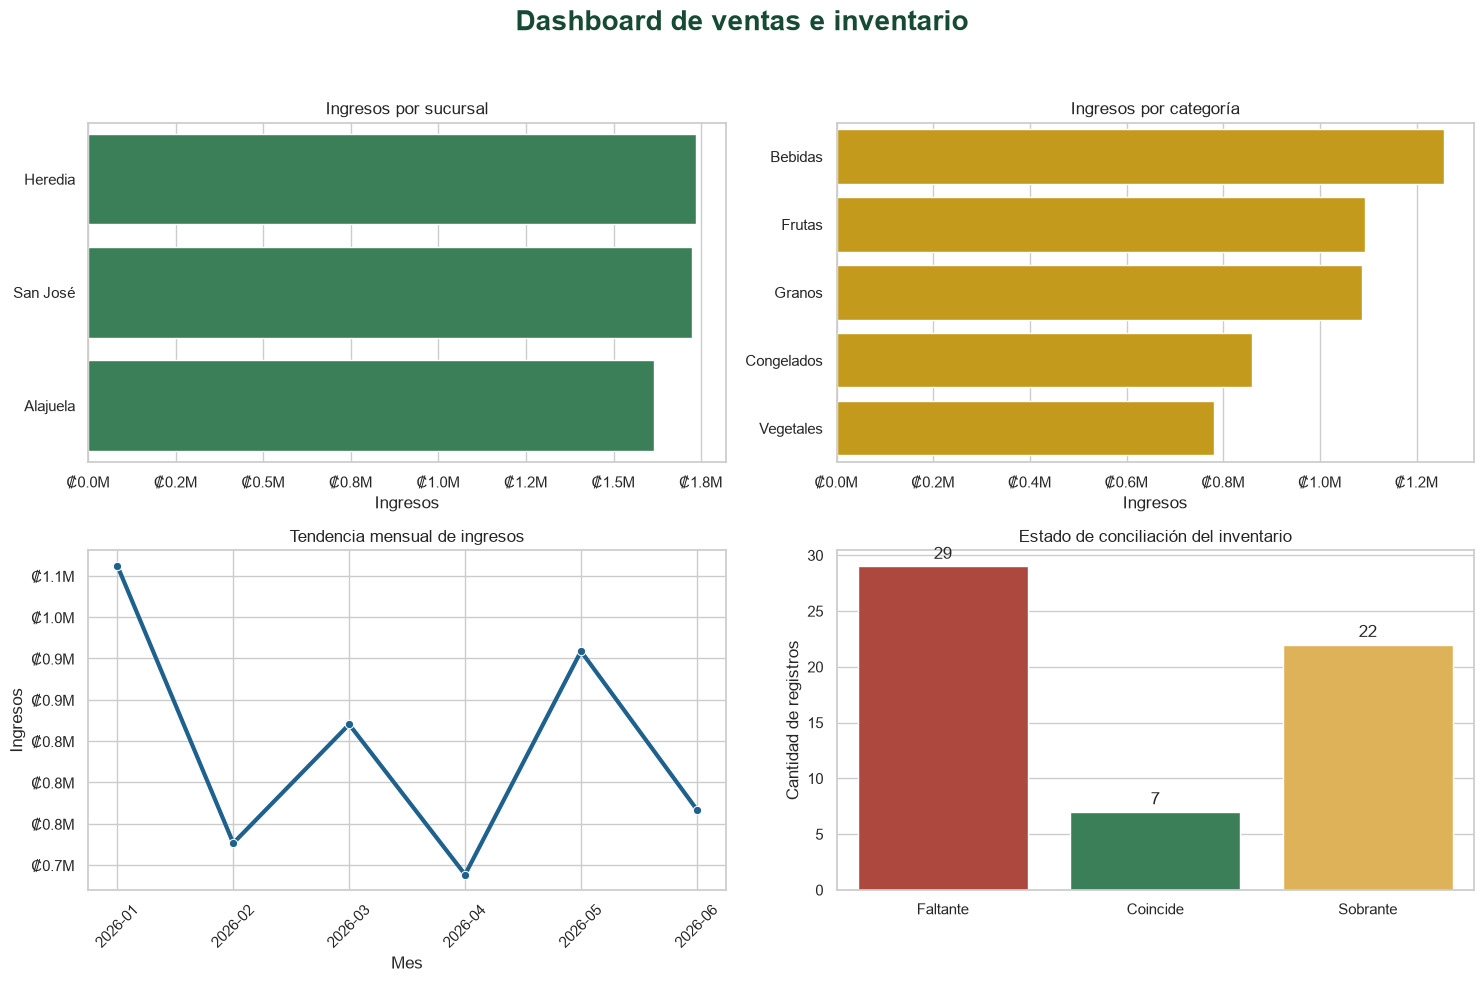

Dashboard guardado en: c:\Users\Henry\OneDrive\Escritorio\python\data-quality-sales-inventory\reports\figures\dashboard_ventas_inventario.png


In [19]:
from matplotlib.ticker import FuncFormatter

# Preparar información para los gráficos
ventas_por_sucursal = (
    ventas_analisis
    .groupby("sucursal", as_index=False)["importe_total"]
    .sum()
    .sort_values("importe_total", ascending=False)
)

ventas_por_categoria = (
    ventas_analisis
    .groupby("categoria", as_index=False)["importe_total"]
    .sum()
    .sort_values("importe_total", ascending=False)
)

ventas_analisis["mes"] = (
    ventas_analisis["fecha"]
    .dt.to_period("M")
    .astype(str)
)

ventas_por_mes = (
    ventas_analisis
    .groupby("mes", as_index=False)["importe_total"]
    .sum()
    .sort_values("mes")
)

orden_estados = [
    "Faltante",
    "Coincide",
    "Sobrante"
]

inventario_por_estado = (
    inventario_analisis["estado_stock"]
    .value_counts()
    .reindex(orden_estados, fill_value=0)
    .rename_axis("estado_stock")
    .reset_index(name="registros")
)

# Formato monetario en millones de colones
formato_millones = FuncFormatter(
    lambda valor, posicion:
        f"₡{valor / 1_000_000:.1f}M"
)

# Crear dashboard
fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10)
)

fig.suptitle(
    "Dashboard de ventas e inventario",
    fontsize=20,
    fontweight="bold",
    color="#164A34"
)

# Gráfico 1: ingresos por sucursal
sns.barplot(
    data=ventas_por_sucursal,
    x="importe_total",
    y="sucursal",
    color="#2E8B57",
    ax=axes[0, 0]
)

axes[0, 0].set_title("Ingresos por sucursal")
axes[0, 0].set_xlabel("Ingresos")
axes[0, 0].set_ylabel("")
axes[0, 0].xaxis.set_major_formatter(formato_millones)

# Gráfico 2: ingresos por categoría
sns.barplot(
    data=ventas_por_categoria,
    x="importe_total",
    y="categoria",
    color="#E0A800",
    ax=axes[0, 1]
)

axes[0, 1].set_title("Ingresos por categoría")
axes[0, 1].set_xlabel("Ingresos")
axes[0, 1].set_ylabel("")
axes[0, 1].xaxis.set_major_formatter(formato_millones)

# Gráfico 3: tendencia mensual
sns.lineplot(
    data=ventas_por_mes,
    x="mes",
    y="importe_total",
    marker="o",
    linewidth=3,
    color="#1F618D",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Tendencia mensual de ingresos")
axes[1, 0].set_xlabel("Mes")
axes[1, 0].set_ylabel("Ingresos")
axes[1, 0].yaxis.set_major_formatter(formato_millones)
axes[1, 0].tick_params(axis="x", rotation=45)

# Gráfico 4: estado del inventario
sns.barplot(
    data=inventario_por_estado,
    x="estado_stock",
    y="registros",
    hue="estado_stock",
    palette={
        "Faltante": "#C0392B",
        "Coincide": "#2E8B57",
        "Sobrante": "#F4B942"
    },
    legend=False,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Estado de conciliación del inventario")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Cantidad de registros")

for contenedor in axes[1, 1].containers:
    axes[1, 1].bar_label(
        contenedor,
        padding=3
    )

plt.tight_layout(rect=[0, 0, 1, 0.95])

# Guardar la imagen
ruta_figuras = ruta_proyecto / "reports" / "figures"
ruta_figuras.mkdir(parents=True, exist_ok=True)

ruta_dashboard = (
    ruta_figuras / "dashboard_ventas_inventario.png"
)

plt.savefig(
    ruta_dashboard,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print(f"Dashboard guardado en: {ruta_dashboard}")

## Análisis detallado de resultados

Se calculan rankings de sucursales, productos e impacto del inventario para sustentar las conclusiones y recomendaciones del proyecto.

In [20]:
# Resultados por sucursal
resumen_sucursales = (
    ventas_analisis
    .groupby("sucursal", as_index=False)
    .agg(
        transacciones=("venta_id", "nunique"),
        unidades_vendidas=("cantidad", "sum"),
        ingresos=("importe_total", "sum")
    )
    .sort_values("ingresos", ascending=False)
)

resumen_sucursales["participacion_ingresos"] = (
    resumen_sucursales["ingresos"]
    / resumen_sucursales["ingresos"].sum()
    * 100
).round(2)

# Ranking de productos
ranking_productos = (
    ventas_analisis
    .groupby(
        [
            "producto_id",
            "nombre_producto",
            "categoria"
        ],
        as_index=False
    )
    .agg(
        unidades_vendidas=("cantidad", "sum"),
        ingresos=("importe_total", "sum")
    )
    .sort_values("ingresos", ascending=False)
)

# Impacto del inventario por sucursal
inventario_temporal = inventario_analisis.copy()

inventario_temporal["con_diferencia"] = (
    inventario_temporal["diferencia_stock"] != 0
)

resumen_inventario_sucursal = (
    inventario_temporal
    .groupby("sucursal", as_index=False)
    .agg(
        productos_revisados=("producto_id", "count"),
        productos_con_diferencia=(
            "con_diferencia",
            "sum"
        ),
        diferencia_neta_unidades=(
            "diferencia_stock",
            "sum"
        ),
        impacto_monetario=(
            "impacto_absoluto",
            "sum"
        )
    )
    .sort_values(
        "impacto_monetario",
        ascending=False
    )
)

resumen_inventario_sucursal[
    "porcentaje_con_diferencia"
] = (
    resumen_inventario_sucursal[
        "productos_con_diferencia"
    ]
    / resumen_inventario_sucursal[
        "productos_revisados"
    ]
    * 100
).round(2)

print("RESULTADOS POR SUCURSAL")
display(
    resumen_sucursales.style.format({
        "ingresos": "₡{:,.2f}",
        "participacion_ingresos": "{:.2f}%"
    })
)

print("TOP 5 PRODUCTOS POR INGRESOS")
display(
    ranking_productos.head(5).style.format({
        "ingresos": "₡{:,.2f}"
    })
)

print("IMPACTO DEL INVENTARIO POR SUCURSAL")
display(
    resumen_inventario_sucursal.style.format({
        "impacto_monetario": "₡{:,.2f}",
        "porcentaje_con_diferencia": "{:.2f}%"
    })
)

RESULTADOS POR SUCURSAL


,sucursal,transacciones,unidades_vendidas,ingresos,participacion_ingresos
1,Heredia,160,1185,"₡1,734,179.99",34.18%
2,San José,167,1230,"₡1,724,364.79",33.99%
0,Alajuela,164,1163,"₡1,614,848.20",31.83%


TOP 5 PRODUCTOS POR INGRESOS


,producto_id,nombre_producto,categoria,unidades_vendidas,ingresos
19,P020,Pulpa De Fresa,Congelados,216,"₡505,639.81"
15,P016,Jugo De Piña,Bebidas,218,"₡371,059.10"
18,P019,Pulpa De Mango,Congelados,154,"₡353,381.20"
14,P015,Jugo De Naranja,Bebidas,183,"₡320,626.39"
17,P018,Té Frío,Bebidas,254,"₡308,057.12"


IMPACTO DEL INVENTARIO POR SUCURSAL


,sucursal,productos_revisados,productos_con_diferencia,diferencia_neta_unidades,impacto_monetario,porcentaje_con_diferencia
0,Alajuela,20,17,69,"₡179,600.00",85.00%
2,San José,20,18,-2,"₡87,900.00",90.00%
1,Heredia,18,16,-7,"₡55,200.00",88.89%


## Conclusiones ejecutivas

### Desempeño comercial

Los ingresos totales alcanzaron **₡5,073,392.98**, correspondientes a **491 transacciones válidas** y **3,578 unidades vendidas**.

La distribución de ingresos entre sucursales es equilibrada:

- **Heredia:** ₡1,734,179.99, equivalente al 34.18%.
- **San José:** ₡1,724,364.79, equivalente al 33.99%.
- **Alajuela:** ₡1,614,848.20, equivalente al 31.83%.

Heredia lidera por ingresos, aunque San José registra más transacciones y unidades vendidas. Alajuela presenta una participación ligeramente menor, por lo que existe una oportunidad para revisar su combinación de productos y estrategia comercial.

### Productos destacados

El producto con mayores ingresos es **Pulpa de Fresa (P020)**, con **216 unidades vendidas** y **₡505,639.81** generados.

Los cinco productos principales pertenecen a las categorías de **Bebidas** y **Congelados**, lo que indica que estas líneas tienen una participación relevante en el desempeño comercial.

### Conciliación de inventario

Se identificaron diferencias en **51 de los 58 registros de inventario analizados**, equivalente al **87.9%**. La diferencia absoluta asciende a **230 unidades**, con un impacto monetario estimado de **₡322,700.00**.

- **Alajuela** presenta el mayor impacto monetario: ₡179,600.00 y una diferencia neta positiva de 69 unidades.
- **San José** tiene el mayor porcentaje de productos con diferencias: 90%.
- **Heredia** presenta una diferencia neta negativa de 7 unidades.

Las diferencias netas pueden ocultar compensaciones entre faltantes y sobrantes. Por esta razón, el impacto absoluto proporciona una medición más útil del riesgo operativo.

## Recomendaciones

1. Implementar conteos cíclicos de inventario, priorizando Alajuela y San José.
2. Investigar individualmente los productos con mayor impacto monetario.
3. Automatizar la conciliación entre el stock del sistema y los conteos físicos.
4. Incorporar validaciones obligatorias para productos, fechas, cantidades y precios.
5. Utilizar catálogos maestros para evitar variaciones en nombres de sucursales y categorías.
6. Crear alertas para diferencias de inventario superiores a un límite definido.
7. Revisar la estrategia comercial de Alajuela para reducir la diferencia de ingresos frente a las demás sucursales.

## Resultado del proceso de calidad

El proceso permitió:

- Eliminar registros duplicados.
- Normalizar categorías y nombres de sucursales.
- Corregir valores faltantes recuperables.
- Detectar productos inexistentes en el catálogo.
- Corregir precios inválidos utilizando reglas documentadas.
- Excluir registros que no podían recuperarse de manera confiable.
- Generar archivos limpios para Python, Excel y Power Query.
- Construir indicadores y visualizaciones para apoyar decisiones.

> **Nota:** Los datos utilizados son sintéticos y fueron creados exclusivamente con fines académicos y de portafolio. No contienen información real ni confidencial.

## Entregables finales del análisis

Se exportan las tablas enriquecidas y un reporte de Excel con indicadores, rankings, resultados por sucursal y validaciones de calidad.

In [21]:
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

# Rutas de salida
ruta_ventas_analisis = (
    ruta_processed / "ventas_analisis.csv"
)

ruta_inventario_analisis = (
    ruta_processed / "inventario_analisis.csv"
)

ruta_reporte_excel = (
    ruta_proyecto / "reports" / "reporte_analisis.xlsx"
)

# Exportar archivos enriquecidos para Power Query
ventas_analisis.to_csv(
    ruta_ventas_analisis,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

inventario_analisis.to_csv(
    ruta_inventario_analisis,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

# Crear reporte de Excel
with pd.ExcelWriter(
    ruta_reporte_excel,
    engine="openpyxl",
    date_format="YYYY-MM-DD",
    datetime_format="YYYY-MM-DD"
) as writer:
    indicadores.to_excel(
        writer,
        sheet_name="Indicadores",
        index=False
    )

    resumen_sucursales.to_excel(
        writer,
        sheet_name="Sucursales",
        index=False
    )

    ranking_productos.to_excel(
        writer,
        sheet_name="Productos",
        index=False
    )

    resumen_inventario_sucursal.to_excel(
        writer,
        sheet_name="Inventario sucursal",
        index=False
    )

    validaciones_finales.to_excel(
        writer,
        sheet_name="Validaciones",
        index=False
    )

    ventas_analisis.to_excel(
        writer,
        sheet_name="Ventas detalle",
        index=False
    )

    inventario_analisis.to_excel(
        writer,
        sheet_name="Inventario detalle",
        index=False
    )

# Aplicar formato profesional
libro = load_workbook(ruta_reporte_excel)

relleno_encabezado = PatternFill(
    fill_type="solid",
    fgColor="1F6B4F"
)

fuente_encabezado = Font(
    color="FFFFFF",
    bold=True
)

for hoja in libro.worksheets:
    hoja.freeze_panes = "A2"
    hoja.auto_filter.ref = hoja.dimensions

    for celda in hoja[1]:
        celda.fill = relleno_encabezado
        celda.font = fuente_encabezado
        celda.alignment = Alignment(
            horizontal="center",
            vertical="center"
        )

    for columna in hoja.columns:
        letra_columna = get_column_letter(
            columna[0].column
        )

        ancho = max(
            len(str(celda.value))
            if celda.value is not None else 0
            for celda in columna
        )

        hoja.column_dimensions[
            letra_columna
        ].width = min(ancho + 2, 35)

# Formatos monetarios
columnas_monetarias = {
    "Sucursales": ["ingresos"],
    "Productos": ["ingresos"],
    "Inventario sucursal": ["impacto_monetario"],
    "Ventas detalle": [
        "precio_unitario",
        "importe_total",
        "precio_estandar"
    ],
    "Inventario detalle": [
        "precio_estandar",
        "valor_diferencia",
        "impacto_absoluto"
    ]
}

for nombre_hoja, nombres_columnas in columnas_monetarias.items():
    hoja = libro[nombre_hoja]

    encabezados = {
        celda.value: celda.column
        for celda in hoja[1]
    }

    for nombre_columna in nombres_columnas:
        numero_columna = encabezados.get(nombre_columna)

        if numero_columna is not None:
            for fila in range(2, hoja.max_row + 1):
                hoja.cell(
                    fila,
                    numero_columna
                ).number_format = '₡#,##0.00'

libro.save(ruta_reporte_excel)

print("ENTREGABLES GENERADOS:\n")
print(f"- {ruta_ventas_analisis.name}")
print(f"- {ruta_inventario_analisis.name}")
print(f"- {ruta_reporte_excel.name}")
print(f"\nReporte guardado en: {ruta_reporte_excel}")

ENTREGABLES GENERADOS:

- ventas_analisis.csv
- inventario_analisis.csv
- reporte_analisis.xlsx

Reporte guardado en: c:\Users\Henry\OneDrive\Escritorio\python\data-quality-sales-inventory\reports\reporte_analisis.xlsx
